# **Practical assignment on Topic 5**



In your assigmnet, you will use the following **data** (*do not modify the code*):

In [16]:
### DO NOT MODIFY THIS CODE. JUST RUN IT.

from sklearn.datasets import make_blobs

# creating the dataset
X, y = make_blobs(n_samples=70, centers=[(0, 0), (3, 4), (2, -5), (6, 3), (8, -1), (6, -6)], n_features=2, cluster_std=1.5, random_state=42)
y[y == 2] = 1
y[y == 3] = 0
y[y == 4] = 1
y[y == 5] = 0

# standardizing the dataset
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Your assignment consists of **two tasks**:

**Task 1**
* **Step 1.** Plot the dataset in a 2D plot.
* **Step 2.** Use stratified 10-fold cross-validation to compute macro-averaged F1-score evaluating 32 models that you get by creating polynomials from degree 1 to 4 and regularizing each of them using the following C values: `[0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]` (don't worry if you get a couple of warning messages about convergence). Print all 32 F1-scores on screen. Store all 32 F1-scores in a 2D array.
* **Step 3.** Use the array from Step 2 to plot a single diagram showing dependence of F1 on C for all four models. The diagram should contain four curves. The horizontal axis (C) should be log-scaled.
* **Step 4.** Plot four diagrams, in each showing all the data points as well as the decision boundaries for one of the four models when its best C value is used.

**Task 2**
* Choose the one model you consider the best. Show its confusion matrix (it should be computed using the same stratified 10-fold cross-validation process as already used in Task 1).
* Write conclusions about all the diagrams plotted in Tasks 1 and 2, especially the F1 vs. C diagram, decision boundaries, and confusion matrix.

*While doing the tasks you are allowed to use only those function libraries and only those scikit-learn functions that were already used in the lectures so far.*

**After the tasks are done, submit this file. Do not clear it's output - all print-outs and figures should be left in the file. All your code should be fully runnable in the order of appearance and it should produce exactly the same output that is present in your print-outs and figures you left in the file.**

---
# **Task 1**

## **Step 1. Plot the dataset in a 2D plot**

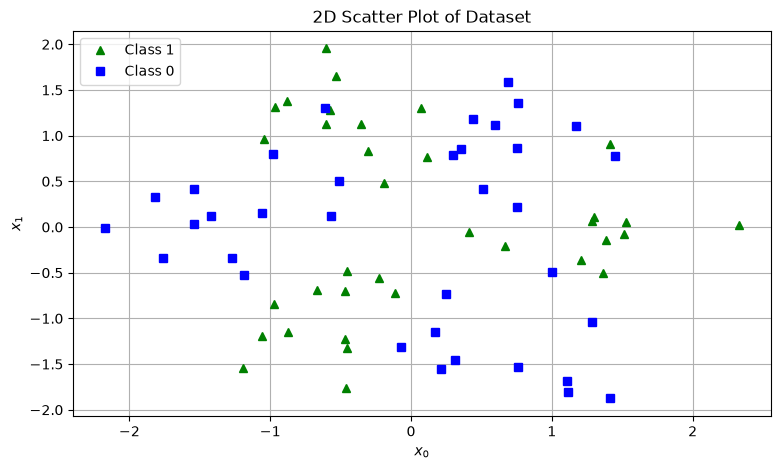

In [17]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Class 1")
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Class 0")
plt.xlabel("$x_0$")
plt.ylabel("$x_1$")
plt.title("2D Scatter Plot of Dataset")
plt.legend(loc="upper left")
plt.grid()
plt.show()

## **Step 2. Stratified 10-fold cross-validation across polynomial degrees (1 to 4) and C values**

In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score

degrees = [1, 2, 3, 4]
Cs = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]

skfcv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# storing macro averaged f1 scores
f1_scores = np.empty((len(degrees), len(Cs)))

print("Computed macro averaged F1-Scores for 32 models:")
for d_idx, degree in enumerate(degrees):
    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly_features.fit_transform(X)

    for c_idx, C in enumerate(Cs):
        log_reg = LogisticRegression(C=C, random_state=42)
        yHat = cross_val_predict(log_reg, X_poly, y, cv=skfcv)
        score = f1_score(y, yHat, average='macro')
        f1_scores[d_idx, c_idx] = score
        print(f"Degree {degree}, C = {C:<8} -> Macro F1-score: {score:.4f}")

print("\n2D array of F1-scores:")
print(f1_scores)

Computed macro averaged F1-Scores for 32 models:
Degree 1, C = 0.0001   -> Macro F1-score: 0.4286
Degree 1, C = 0.001    -> Macro F1-score: 0.4286
Degree 1, C = 0.01     -> Macro F1-score: 0.3714
Degree 1, C = 0.1      -> Macro F1-score: 0.3284
Degree 1, C = 1        -> Macro F1-score: 0.2999
Degree 1, C = 10       -> Macro F1-score: 0.3137
Degree 1, C = 100      -> Macro F1-score: 0.3137
Degree 1, C = 1000     -> Macro F1-score: 0.3137
Degree 2, C = 0.0001   -> Macro F1-score: 0.4286
Degree 2, C = 0.001    -> Macro F1-score: 0.4286
Degree 2, C = 0.01     -> Macro F1-score: 0.3980
Degree 2, C = 0.1      -> Macro F1-score: 0.4142
Degree 2, C = 1        -> Macro F1-score: 0.3694
Degree 2, C = 10       -> Macro F1-score: 0.3668
Degree 2, C = 100      -> Macro F1-score: 0.3668
Degree 2, C = 1000     -> Macro F1-score: 0.3668
Degree 3, C = 0.0001   -> Macro F1-score: 0.4286
Degree 3, C = 0.001    -> Macro F1-score: 0.5711
Degree 3, C = 0.01     -> Macro F1-score: 0.6893
Degree 3, C = 0.1   

/Users/wilmesmeierj/checkout/machine-learning-algorithms/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/wilmesmeierj/checkout/machine-learning-algorithms/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale t

## **Step 3. Diagram showing dependence of F1 on C for all four models**

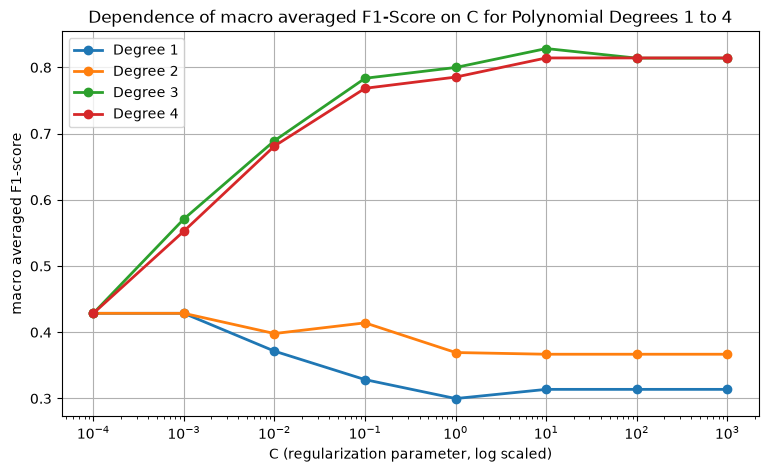

In [19]:
plt.figure(figsize=(9, 5))

for d_idx, degree in enumerate(degrees):
    plt.plot(Cs, f1_scores[d_idx], "-o", label=f"Degree {degree}", linewidth=2)

plt.xscale('log')
plt.xlabel("C (regularization parameter, log scaled)")
plt.ylabel("macro averaged F1-score")
plt.title("Dependence of macro averaged F1-Score on C for Polynomial Degrees 1 to 4")
plt.legend(loc="best")
plt.grid()
plt.show()

## **Step 4. Decision boundaries for each of the four models using its best C value**

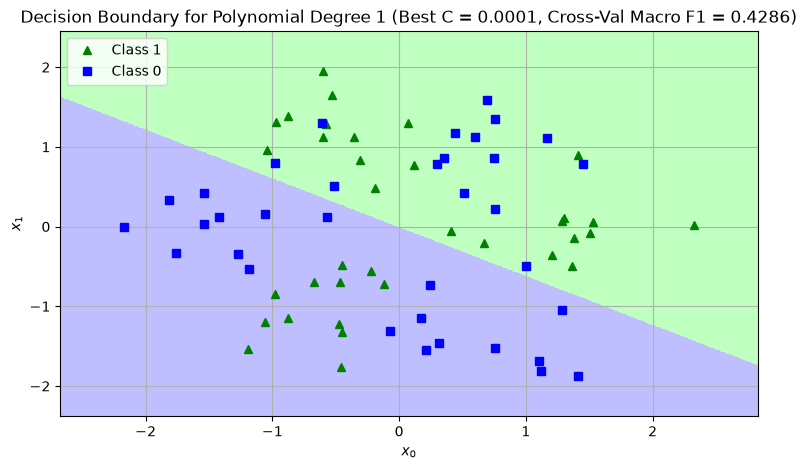

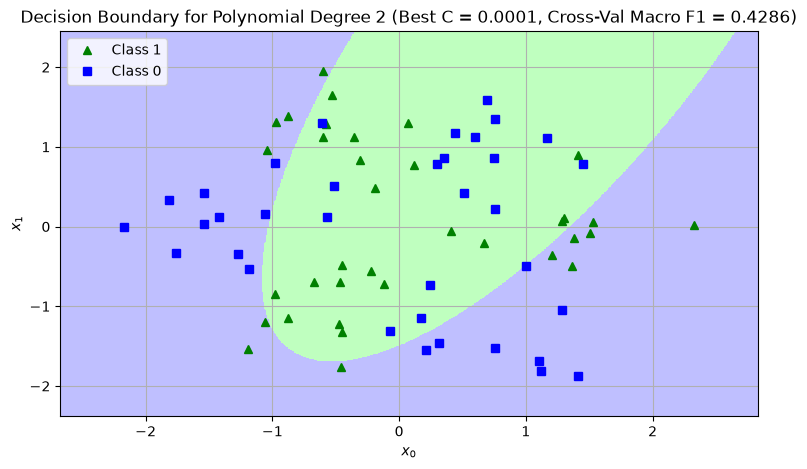

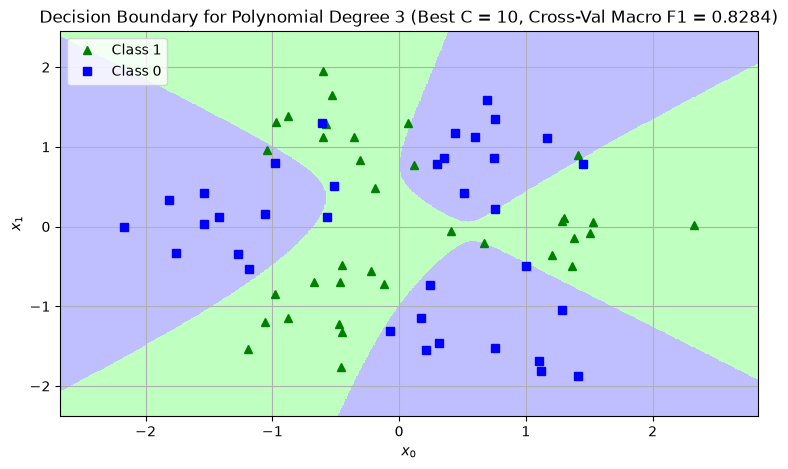

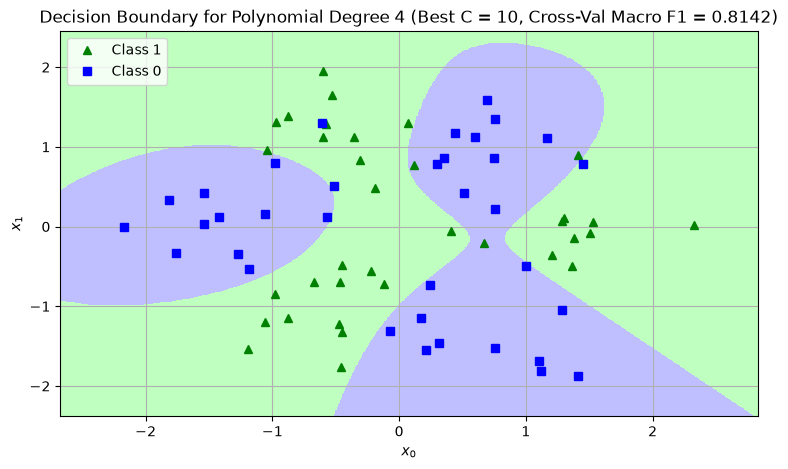

In [20]:
from matplotlib.colors import ListedColormap

# get best C index and value for each degree
best_c_indices = np.argmax(f1_scores, axis=1)

x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 500).reshape(-1, 1),
                     np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 500).reshape(-1, 1))
X_grid = np.c_[x0.ravel(), x1.ravel()]
custom_cmap = ListedColormap(["#bfbfff", "#bfffbf"])

for d_idx, degree in enumerate(degrees):
    best_c_idx = best_c_indices[d_idx]
    best_C = Cs[best_c_idx]
    best_score = f1_scores[d_idx, best_c_idx]

    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly_features.fit_transform(X)
    X_grid_poly = poly_features.transform(X_grid)
    
    log_reg = LogisticRegression(C=best_C, random_state=42)
    log_reg.fit(X_poly, y)
    
    zz = log_reg.predict(X_grid_poly).reshape(x0.shape)
    
    plt.figure(figsize=(9, 5))
    plt.contourf(x0, x1, zz, cmap=custom_cmap)
    plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Class 1")
    plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Class 0")
    plt.xlabel("$x_0$")
    plt.ylabel("$x_1$")
    plt.title(f"Decision Boundary for Polynomial Degree {degree} (Best C = {best_C}, Cross-Val Macro F1 = {best_score:.4f})")
    plt.legend(loc="upper left")
    plt.grid()
    plt.show()

---
# **Task 2**

## **Confusion Matrix for the Best Model**

Confusion Matrix:
[[30  5]
 [ 7 28]]

Confusion Matrix Display:


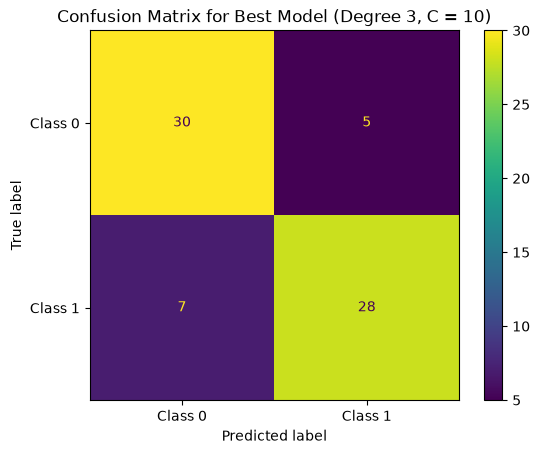

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Degree 3 with C = 10 achieves the highest macro F1-score (0.8284)
best_degree = 3
best_C = 10

poly_features_best = PolynomialFeatures(degree=best_degree, include_bias=False)
X_poly_best = poly_features_best.fit_transform(X)

best_model = LogisticRegression(C=best_C, random_state=42)
yHat_best = cross_val_predict(best_model, X_poly_best, y, cv=skfcv)

print("Confusion Matrix:")
cm = confusion_matrix(y, yHat_best)
print(cm)

print("\nConfusion Matrix Display:")
ConfusionMatrixDisplay.from_predictions(y, yHat_best, display_labels=['Class 0', 'Class 1'])
plt.title(f"Confusion Matrix for Best Model (Degree {best_degree}, C = {best_C})")
plt.show()

## Conclusions
### Task 1 Step 1: Dataset Distribution
- The dataset holds 70 samples balanced equally between to classes (35 samples each of class 0 and class 1) forming clusters/blobs
- Visualized in 2D it is possible to see, that clusters of class 0 and class 1 alternate and interleave non-linearly. Because beeing not linearly separable, standard linear or quadratic models cannot solve this classification problem. Higher-degree non-linear polynomial features are needed.

### Task 1 Step 2 and 3: F1 vs C Dependence
- Linear and quadratic (Degree 1 and 2) underfit severely across all tested values of C. At very small C values (extreme strong regularization), the models predict a single dominant class for most points, giving a baseline macro f1 score of around 0.4286. Increasing C does not improve the performance due to linear/quadratic boundaries which lack the flexibility to separate the interleaved clusters, resulting in f1 scores from around 0.30 to 0.41.
- Models with polynomial degree 3 and 4 have sufficient capacity to capture the non-linear cluster structure. At very low C values, heavy regularization restricts the model, leading to the same underfitting baseline of around 0.4286. Increasing C up to C = 10, the macro f1 score increases a lot, peaking at C = 10 with f1 of 0.8284 for Degree 3 and 0.8142 for Degree 4. With a higher C the f1 scores slightly decrease and levels at around 0.8139 (for Degree 3) because of slight overfitting and sample noises impacting more due to lacking regularization.

### Task 1 Step 4: Decision Boundaries
- For Degree 1 (with C = 0.0001) a flat partition is produced, failing to divide the interleaved clusters, demonstrating underfitting.
- For Degree 2 (with C = 0.0001) a very restricted quadratic partition is produced which still cannot separate the cluster pattern.
- Degree 3 (with C = 10) produces a smooth, well-shaped non-linear boundary that encloses and separates different cluster regions of class 1 and class 0.
- Finally Degree 4 (with C = 10) produces a multi-region decision boundary as well, but slightly more complex curvature. It introduces a little more unnecessary fragmentation leading to a score slightly under Degree 3 model.

### Task 2: Best Model Selection & Confusion Matrix
- The best model choice is the polynomial logistic regression of Degree 3 with regularization of C = 10. It achieves the highest 10-fold cross-validated macro averaged f1 score of about 0.8284. It has the best balance between model complexity and generalization.
- The confusion matrix shows 30 samples correctly classified for class 0 and 28 samples correctly classified as class 1. 5 Samples have been misclassified as class 1 (FP) and 7 samples have been misclassified as class 0 (FN). That achieves a overall cross-validated accuracy of 58/70 equals around 82.86%. Classification errors are balanced between both classes, confirming that the model performs robustly across all folds without tending to one of the classes.

Assignee: Jakob Benedikt Wilmesmeier